In [1]:
import napari
import numpy as np
from skimage import io

import h5py
import matplotlib.pyplot as plt

## Record drift with viewer (local)

In [2]:
HEADPATH = '/home/gutil/scratch/2025-06-28_Manual-Drift-Recording/'
images_experiment_filename = HEADPATH + 'Experiment_crop_XY-All_T-Last_For-Drift.hdf5'
images_barcodes_filename = HEADPATH + 'Barcodes_crop_XY-All_T-01_For-Drift.hdf5'

In [3]:
# Read the images from the HDF5 files
with h5py.File(images_experiment_filename, 'r') as f:
    images_experiment = np.array(f['data'])

with h5py.File(images_barcodes_filename, 'r') as f:
    images_barcodes = np.array(f['data'])

In [ ]:
# Open Napari viewer
viewer = napari.Viewer()

# Add the images to the viewer

layer_barcodes = viewer.add_image(images_barcodes,
                                     name='Barcodes',
                                     # colormap='gray',
                                     opacity=1,
                                     contrast_limits=(0, 5000),
                                     )

layer_experiment = viewer.add_image(images_experiment,
                                     name='Experiment',
                                     colormap='red',
                                     opacity=0.5,
                                     contrast_limits=(300, 3000),
                                     )

drift_metadata = {}  # Dictionary to store drift metadata

# Function to record drift after manual alignment and apply to subsequent images
def record_drift(event):

    current_fov = viewer.dims.current_step[0]  # Get the current FOV index
    translation = layer_experiment.affine.translate
    drift_metadata[current_fov] = translation  # Store as [dy, dx] (assuming translation is [0, dy, dx])

    # Apply this drift to subsequent FOVs that haven't been modified yet
    for fov in range(current_fov + 1, viewer.dims.nsteps[0]):
        # if fov not in drift_metadata:
        drift_metadata[fov] = translation

last_fov = viewer.dims.current_step[0]  # Store initial FOV

def on_fov_change(event):
    global last_fov
    current_fov = viewer.dims.current_step[0]

    if current_fov != last_fov:
        # FOV has changed!
        if current_fov not in drift_metadata:
            # If no drift recorded for this FOV, apply the drift from the previous FOV
            if last_fov in drift_metadata:
                layer_experiment.affine.translate = drift_metadata[last_fov]
            else:
                layer_experiment.affine.translate = [0., 0., 0.]
        else:
            layer_experiment.affine.translate = drift_metadata[current_fov]

        layer_experiment.refresh()
        last_fov = current_fov  # Update last_fov to current


layer_experiment.events.affine.connect(record_drift)
viewer.dims.events.current_step.connect(on_fov_change)

# Ensure the viewer starts on the first image (index 0)
viewer.dims.current_step = (0,)

napari.run()

In [6]:
viewer.dims.nsteps[0]

627

<Axes: xlabel='FOV'>

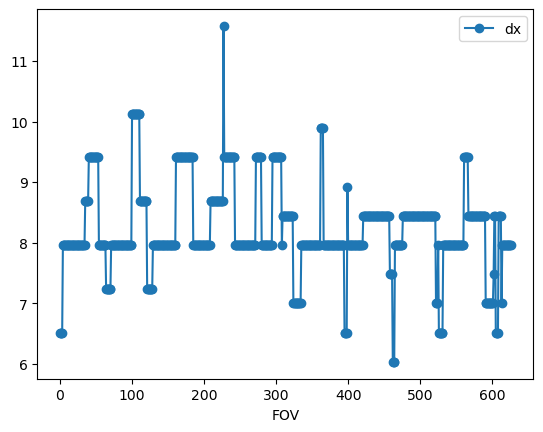

In [39]:
# Get the x and y translation values for all FOVs as numpy arrays
x_translations = np.array([drift_metadata[fov][2] for fov in range(viewer.dims.nsteps[0])])
y_translations = np.array([drift_metadata[fov][1] for fov in range(viewer.dims.nsteps[0])])

# Convert drift_metadata to a pandas dataframe
import pandas as pd
drift_df = pd.DataFrame({
    'FOV': range(viewer.dims.nsteps[0]),
    'dx': x_translations,
    'dy': y_translations
})
drift_df.plot(x='FOV', y='dx', marker='o')

In [ ]:
drift_df.to_pickle(HEADPATH + 'drift_metadata.pkl')

## Check drift with the viewer (local)

In [40]:
# Open a new Napari viewer
translation_viewer = napari.Viewer()

# Add the images to the viewer
translation_layer_barcodes = translation_viewer.add_image(images_barcodes,
                                                          name='Barcodes',
                                                          opacity=1,
                                                          contrast_limits=(0, 5000))

translation_layer_experiment = translation_viewer.add_image(images_experiment,
                                                             name='Experiment',
                                                             colormap='red',
                                                             opacity=0.5,
                                                             contrast_limits=(300, 3000))

# Function to apply translations from drift_metadata
def apply_translation(event):
    current_fov = translation_viewer.dims.current_step[0]  # Get the current FOV index
    if current_fov in drift_metadata:
        translation = drift_metadata[current_fov]
        translation_layer_experiment.affine.translate = translation
        translation_layer_experiment.refresh()

# Connect the function to the viewer's current_step event
translation_viewer.dims.events.current_step.connect(apply_translation)

# Ensure the viewer starts on the first image (index 0)
translation_viewer.dims.current_step = (0,)

napari.run()